<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/sdg_dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dynamics of sustainable development in Bolivia, 2012–2024

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

The *Atlas de los ODS en Bolivia 2026* (Andersen & Argandoña, SDSN Bolivia) measures the Sustainable Development Goals (SDGs) in Bolivia's 343 municipalities and indigenous autonomies at two points in time, near the 2012 and the 2024 population censuses. This notebook asks how sustainable development changed between the two:

1. **Load** the Sustainable Development Index (IDS), the 15 goal indices and multidimensional poverty
2. **Change, 2012–2024**: distributions, maps, the largest gains, and progress weighted by population
3. **Which goals moved**: the goals that advanced and those that retreated
4. **Convergence**: did lagging municipalities catch up (β-convergence), and did the dispersion narrow (σ-convergence)?
5. **Rank mobility**: how much the ordering of municipalities changed
6. **Spatial dynamics**: spatial clustering in each period, and where progress clustered
7. **Takeaways**

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds). Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "geometrics", "mapclassify", "libpysal", "esda"]
           if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import plotly.io as pio

import geo4bolivia as geo
import geometrics as gm

if "google.colab" not in sys.modules:
    pio.renderers.default = "plotly_mimetype+notebook_connected"   # keeps the saved notebook small

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
SEED = 42

## 1. Load the data

| Variable | Dataset | Meaning |
| --- | --- | --- |
| `index_sdg` | `sdg` | Sustainable Development Index (IDS, 0–100): the mean of the 15 goal indices |
| `rank_sdg` | `sdg` | Rank of the IDS among the 343 units (1 = best) |
| `population` | `sdg` | Census population, 2012 and 2024 |
| `index_sdg1` … `index_sdg17` | `sdg01` … `sdg17` | Goal indices (0–100); the Atlas has none for SDG 12 or 14 |
| `sdg1_2_mpi` | `sdg01` | Multidimensional Poverty Index (0–1; **higher = poorer**), from the censuses |

Every index is on a 0–100 scale where 100 means the goal's targets are met: each of the 81 indicators is rescaled between a worst and a best value, a goal index is the mean of its rescaled indicators, and the IDS is the mean of the 15 goal indices.

In [3]:
GOALS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15, 16, 17]
YEARS = [2012, 2024]

sdg = geo.load("sdg", variables=["index_sdg", "rank_sdg", "population"])
long = sdg
for g in GOALS:
    long = long.merge(geo.load(f"sdg{g:02d}", variables=f"index_sdg{g}"), on=["geo_id", "year"])
long = long.merge(geo.load("sdg01", variables="sdg1_2_mpi"), on=["geo_id", "year"])

units = geo.units()
names = units.set_index("geo_id")["name"]
muni = units.loc[units["scale"] == "municipality", ["geo_id", "name", "department_id"]]
muni["department"] = muni["department_id"].map(names)
long = long.merge(muni[["geo_id", "name", "department"]], on="geo_id")

goal_label = {g: geo.dictionary(f"sdg{g:02d}").set_index("variable").loc[f"index_sdg{g}", "label"]
                  .replace(" index (0-100)", "") for g in GOALS}
print(long.shape, "| units:", long["geo_id"].nunique(), "| periods:", sorted(long["year"].unique()))
long.head()

(686, 23) | units: 343 | periods: [np.int64(2012), np.int64(2024)]


,geo_id,year,index_sdg,rank_sdg,population,index_sdg1,index_sdg2,index_sdg3,index_sdg4,index_sdg5,...,index_sdg9,index_sdg10,index_sdg11,index_sdg13,index_sdg15,index_sdg16,index_sdg17,sdg1_2_mpi,name,department
0,BO-01-01-01,2012,40.8,332,10652,11.7,34.9,67.9,29.2,63.9,...,3.8,71.1,18.3,79.3,73.3,81.1,13.3,0.512,Azurduy,Chuquisaca
1,BO-01-01-01,2024,54.5,297,7903,35.7,39.6,74.6,55.4,83.9,...,40.5,70.5,28.6,64.6,71.3,94.9,37.4,0.187,Azurduy,Chuquisaca
2,BO-01-01-02,2012,44.5,287,14261,14.0,34.7,75.1,37.3,71.6,...,8.0,63.8,17.1,83.3,73.4,85.7,23.2,0.452,Tarvita,Chuquisaca
3,BO-01-01-02,2024,53.9,306,16812,38.9,36.1,86.2,56.9,83.5,...,36.4,68.3,25.5,63.8,73.4,94.5,15.6,0.133,Tarvita,Chuquisaca
4,BO-01-02-01,2012,53.6,83,11161,38.9,39.2,85.2,51.6,72.6,...,14.8,81.3,31.1,87.7,80.6,89.8,23.2,0.267,Villa Serrano,Chuquisaca


**Two nominal periods.** The Atlas reports an *initial* value near the 2012 census and a *final* value near the 2024 census, stored here as the years 2012 and 2024. Each indicator has its own reference years, kept in the metadata (`geo:reference_years`): census indicators refer exactly to 2012 and 2024, while indicators from administrative records or surveys are single years or multi-year averages close to them. The tally over the 81 indicators:

In [4]:
ref = pd.DataFrame([
    {"indicator": f["name"], "initial": f["geo:reference_years"]["2012"], "final": f["geo:reference_years"]["2024"]}
    for g in GOALS for f in geo.metadata.fields(f"sdg{g:02d}")
    if f["name"].startswith("sdg") and "geo:reference_years" in f])
print("Indicators:", len(ref))
ref.groupby(["initial", "final"]).size().sort_values(ascending=False).rename("indicators").to_frame()

Indicators: 81


indicators
initial           final                        
2012              2024                       45
2008              2023                        6
average 2012–2014 average 2022–2024           6
average 2011–2013 average 2021–2023           4
                  average 2022–2024           3
2016              2024                        3
average 2013–2015 average 2022–2024           3
2012              2023                        1
2013              2024                        1
2012              2025                        1
average 2010–2012 average 2021–2023           1
2016              2025                        1
2015              2024                        1
                  2021                        1
average 2012–2014 average 2022–2023           1
average 2011–2013 average 2020–2022           1
average 2017–2019 average 2022–2024           1
average 2018–2020 average 2022–2024           1

So "2012" and "2024" are best read as "around the 2012 census" and "around the 2024 census", about twelve years apart.

A wide table (one row per unit) and the boundaries for the maps:

In [5]:
VARS = ["index_sdg", "rank_sdg", "population", "sdg1_2_mpi"] + [f"index_sdg{g}" for g in GOALS]
wide = long.pivot(index="geo_id", columns="year", values=VARS)
wide.columns = [f"{v}_{y}" for v, y in wide.columns]
wide = wide.join(muni.set_index("geo_id")[["name", "department"]])
wide["ids_change"] = wide["index_sdg_2024"] - wide["index_sdg_2012"]
wide["mpi_change"] = wide["sdg1_2_mpi_2024"] - wide["sdg1_2_mpi_2012"]

CRS = geo.config()["equal_area_crs"]                       # metres; simplify to ~500 m for light maps
gdf = geo.boundaries("municipality")[["geo_id", "geometry"]].merge(wide.reset_index(), on="geo_id")
gdf = gdf.to_crs(CRS)
gdf["geometry"] = gdf.simplify(500)
dep_lines = geo.boundaries("department").to_crs(CRS).simplify(500).boundary
gdf.shape

(343, 44)

## 2. Change in the IDS, 2012–2024

### The national picture

The Atlas reports Bolivia's IDS as 57.4 in 2012 and 66.0 in 2024. Municipal averages can be taken with equal weights or weighted by population:

In [6]:
def wmean(x, w):
    return float(np.sum(x * w) / np.sum(w))

summary = pd.DataFrame({
    y: {"mean (equal weights)": wide[f"index_sdg_{y}"].mean(),
        "median": wide[f"index_sdg_{y}"].median(),
        "mean weighted by population": wmean(wide[f"index_sdg_{y}"], wide[f"population_{y}"]),
        "min": wide[f"index_sdg_{y}"].min(),
        "max": wide[f"index_sdg_{y}"].max(),
        "population (millions)": wide[f"population_{y}"].sum() / 1e6}
    for y in YEARS})
summary["change"] = summary[2024] - summary[2012]
summary.round(2)

,2012,2024,change
mean (equal weights),50.12,60.08,9.96
median,49.60,59.80,10.20
mean weighted by population,57.85,66.83,8.98
min,37.20,47.30,10.10
max,70.50,77.30,6.80
population (millions),10.06,11.36,1.31


Units whose IDS rose: 342 of 343; unchanged: 0; fell: 1
Change: mean 9.96, median 9.90, sd 2.91, range -2.7 to 20.5


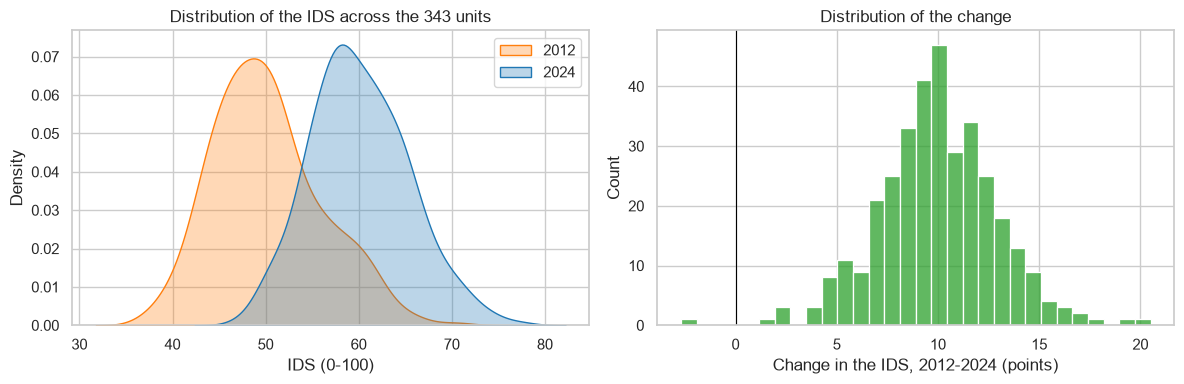

In [7]:
print(f"Units whose IDS rose: {(wide['ids_change'] > 0).sum()} of {len(wide)}; "
      f"unchanged: {(wide['ids_change'] == 0).sum()}; fell: {(wide['ids_change'] < 0).sum()}")
print(f"Change: mean {wide['ids_change'].mean():.2f}, median {wide['ids_change'].median():.2f}, "
      f"sd {wide['ids_change'].std():.2f}, range {wide['ids_change'].min():.1f} to {wide['ids_change'].max():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for y, c in zip(YEARS, ["tab:orange", "tab:blue"]):
    sns.kdeplot(wide[f"index_sdg_{y}"], fill=True, alpha=0.3, color=c, label=str(y), ax=axes[0])
axes[0].set(xlabel="IDS (0-100)", title="Distribution of the IDS across the 343 units")
axes[0].legend()
sns.histplot(wide["ids_change"], bins=30, color="tab:green", ax=axes[1])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set(xlabel="Change in the IDS, 2012-2024 (points)", title="Distribution of the change")
plt.tight_layout()
plt.show()

- **Almost every unit improved.** The IDS rose in 342 of the 343 units; only **San José de Chiquitos** (Santa Cruz) fell, by 2.7 points. The mean gain was 10.0 points (median 9.9, standard deviation 2.9), from −2.7 to +20.5.
- **The whole distribution shifted.** The equal-weighted mean went from 50.1 to 60.1 and the median from 49.6 to 59.8. The minimum rose by 10.1 points (37.2 to 47.3) and the maximum by 6.8 (70.5 to 77.3).
- **Weighted by population**, the IDS went from 57.9 to 66.8 (+9.0). These are close to the Atlas's national values (57.4 and 66.0) without being identical, so the Atlas's national figures are not simply this weighted average. The weighted mean lies above the equal-weighted one because the populous cities score higher. The gap between the two shrank from 7.7 to 6.8 points, because the many small units gained a little more than the cities.

### Maps

Both periods share the same classes (quantiles of the pooled values), so colours are comparable; the change uses its own natural breaks.

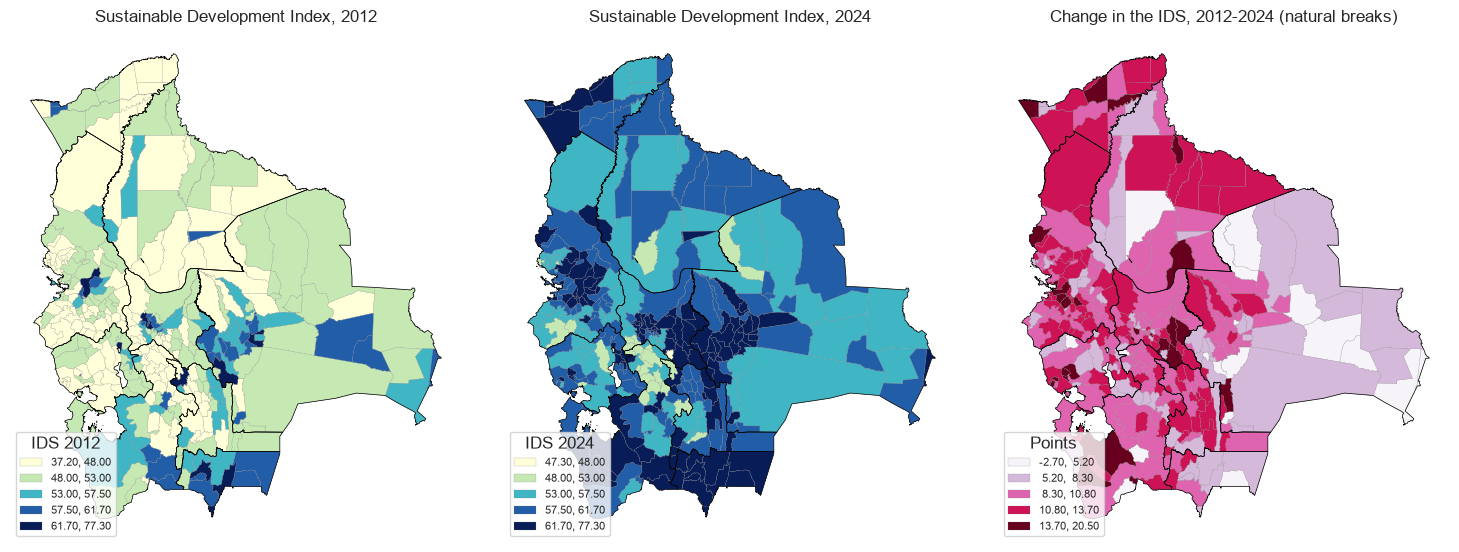

In [8]:
import mapclassify

pooled = np.concatenate([gdf["index_sdg_2012"], gdf["index_sdg_2024"]])
bins = {"bins": list(mapclassify.Quantiles(pooled, k=5).bins)}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, y in zip(axes, YEARS):
    gdf.plot(column=f"index_sdg_{y}", scheme="user_defined", classification_kwds=bins, cmap="YlGnBu",
             edgecolor="grey", linewidth=0.15, legend=True,
             legend_kwds={"title": f"IDS {y}", "loc": "lower left", "fontsize": 8}, ax=ax)
    ax.set_title(f"Sustainable Development Index, {y}")
gdf.plot(column="ids_change", scheme="FisherJenks", k=5, cmap="PuRd", edgecolor="grey", linewidth=0.15,
         legend=True, legend_kwds={"title": "Points", "loc": "lower left", "fontsize": 8}, ax=axes[2])
axes[2].set_title("Change in the IDS, 2012-2024 (natural breaks)")
for ax in axes:
    dep_lines.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

In 2012 the lowest values (yellow) covered most of the Amazonian north (Pando, Beni and northern La Paz) and much of the highlands of Oruro and Potosí; the highest were in the department capitals, the valleys of Cochabamba and Chuquisaca, and Tarija. By 2024 most units had moved up one or two classes. The change map shows the largest gains in the north, the La Paz altiplano, the Cochabamba and Chuquisaca valleys and parts of Oruro, and the smallest in eastern Santa Cruz (the Chiquitania and the border with Brazil) and parts of central Beni.

### Largest gains and the units that fell

In [9]:
cols = ["name", "department", "index_sdg_2012", "index_sdg_2024", "ids_change"]
print("Largest gains:")
print(wide.nlargest(10, "ids_change")[cols].to_string(index=False))
print("\nSmallest gains:")
print(wide.nsmallest(5, "ids_change")[cols].to_string(index=False))

Largest gains:
                      name department  index_sdg_2012  index_sdg_2024  ids_change
      Cruz de Machacamarca      Oruro            42.9            63.4        20.5
                  Carangas      Oruro            43.4            62.8        19.4
                    Sicaya Cochabamba            42.8            60.4        17.6
Villa Gualberto Villarroel Cochabamba            43.4            60.3        16.9
              Todos Santos      Oruro            44.4            61.2        16.8
                Santiváñez Cochabamba            51.5            68.0        16.5
                 San Pedro      Pando            41.7            57.9        16.2
                  Mecapaca     La Paz            50.6            66.7        16.1
                Santa Rosa      Pando            48.2            63.8        15.6
                  Bolpebra      Pando            46.2            61.7        15.5

Smallest gains:
                 name department  index_sdg_2012  index_sdg_2024  

In [10]:
by_dep = (wide.groupby("department")
              .apply(lambda d: pd.Series({
                  "units": len(d),
                  "IDS 2012": wmean(d["index_sdg_2012"], d["population_2012"]),
                  "IDS 2024": wmean(d["index_sdg_2024"], d["population_2024"]),
                  "mean change": d["ids_change"].mean(),
                  "min change": d["ids_change"].min(),
                  "max change": d["ids_change"].max()})))
by_dep["change (pop.-weighted)"] = by_dep["IDS 2024"] - by_dep["IDS 2012"]
by_dep.sort_values("mean change", ascending=False).round(1)

,units,IDS 2012,IDS 2024,mean change,min change,max change,change (pop.-weighted)
department,,,,,,,
Pando,15.0,54.0,63.2,11.5,7.3,16.2,9.2
Cochabamba,48.0,59.0,68.1,10.9,6.4,17.6,9.1
Chuquisaca,29.0,55.6,66.7,10.8,7.4,13.7,11.1
La Paz,87.0,58.7,68.2,10.6,6.5,16.1,9.6
Oruro,35.0,56.0,64.8,10.1,4.5,20.5,8.8
Beni,20.0,52.4,60.3,9.9,4.8,15.2,8.0
Potosí,42.0,50.9,60.6,9.5,2.5,14.6,9.7
Tarija,11.0,62.6,70.1,8.1,4.4,12.2,7.5
Santa Cruz,56.0,59.4,67.4,7.8,-2.7,14.4,8.0


- **The largest gains** were in units that started low (IDS 41.7–51.5 in 2012): Cruz de Machacamarca (+20.5) and Carangas (+19.4) on the Oruro altiplano, the two largest gains in the country, followed by Sicaya (+17.6), Villa Gualberto Villarroel (+16.9) and Santiváñez (+16.5) in Cochabamba, Todos Santos in Oruro (+16.8), San Pedro, Santa Rosa and Bolpebra in Pando (+15.5 to +16.2) and Mecapaca in La Paz (+16.1).
- **The smallest changes** are concentrated in Santa Cruz: San José de Chiquitos (−2.7, the only fall), Roboré (+1.2), Puerto Suárez (+2.3) and Ascención de Guarayos (+2.6), with Atocha (Potosí, +2.5).
- **By department**, the average unit gained most in Pando (+11.5), Cochabamba (+10.9) and Chuquisaca (+10.8), and least in Santa Cruz (+7.8) and Tarija (+8.1). Weighted by population, Chuquisaca gained most (+11.1) and Tarija least (+7.5). Tarija has the highest population-weighted IDS in both periods (62.6 and 70.1); Potosí in 2012 (50.9) and Beni in 2024 (60.3) the lowest.

### Progress weighted by population

A gain of 20 points in a municipality of 3,000 people and one of 5 points in a city of a million mean very different things for the number of people affected. The Atlas calls the second kind *avances masivos*, "massive advances". A simple measure is the gain in points times the 2024 population ("person-points"):

In [11]:
wide["person_points"] = wide["ids_change"] * wide["population_2024"]
total = wide["person_points"].sum()
top = wide.nlargest(10, "person_points")[["name", "department", "population_2024", "ids_change", "person_points"]]
top["share of total (%)"] = 100 * top["person_points"] / total
print(f"Total: {total / 1e6:.1f} million person-points; average gain per person: "
      f"{total / wide['population_2024'].sum():.2f} points")
print(f"Top 10 units: {top['share of total (%)'].sum():.1f}% of the person-points, "
      f"{100 * top['population_2024'].sum() / wide['population_2024'].sum():.1f}% of the 2024 population")
top.assign(person_points=top["person_points"] / 1e6).round(2).rename(
    columns={"person_points": "person-points (millions)"})

Total: 103.9 million person-points; average gain per person: 9.14 points
Top 10 units: 46.4% of the person-points, 46.7% of the 2024 population


,name,department,population_2024,ids_change,person-points (millions),share of total (%)
geo_id,,,,,,
BO-08-01-05,Santa Cruz de la Sierra,Santa Cruz,1610982.0,8.7,14.02,13.49
BO-04-17-02,El Alto,La Paz,885825.0,12.3,10.90,10.49
BO-04-17-04,Nuestra Señora de La Paz,La Paz,757431.0,6.8,5.15,4.96
BO-02-08-01,Cochabamba,Cochabamba,665505.0,7.6,5.06,4.87
BO-01-06-02,Sucre,Chuquisaca,296746.0,10.2,3.03,2.91
BO-05-03-03,Oruro,Oruro,298350.0,8.5,2.54,2.44
BO-02-09-02,Sacaba,Cochabamba,219092.0,10.6,2.32,2.23
BO-09-03-01,Tarija,Tarija,238749.0,8.1,1.93,1.86
BO-07-16-01,Potosí,Potosí,218702.0,8.0,1.75,1.68


The gains add up to 103.9 million person-points, an average of 9.1 points per person living in Bolivia in 2024. The ten largest contributions all come from cities, and together they account for 46.4% of the total, about their share of the population (46.7%): progress in the big cities was roughly proportional to their size. **Santa Cruz de la Sierra** contributes most (13.5%, a gain of 8.7 points for 1.6 million people). **El Alto** is the clearest "massive advance": it gained 12.3 points, more than the national average, for 886,000 people, 10.5% of the total. Nuestra Señora de La Paz gained only 6.8 points.

## 3. Which goals moved

The mean of each goal index across the 343 units (equal weights) and weighted by each period's population:

In [12]:
rows = []
for g in GOALS:
    a, b = wide[f"index_sdg{g}_2012"], wide[f"index_sdg{g}_2024"]
    rows.append({"goal": f"SDG {g}", "name": goal_label[g],
                 "mean 2012": a.mean(), "mean 2024": b.mean(), "change": b.mean() - a.mean(),
                 "pop.-weighted 2012": wmean(a, wide["population_2012"]),
                 "pop.-weighted 2024": wmean(b, wide["population_2024"]),
                 "units that rose (%)": 100 * (b > a).mean(),
                 "units that fell (%)": 100 * (b < a).mean()})
goals = pd.DataFrame(rows).set_index("goal")
goals["pop.-weighted change"] = goals["pop.-weighted 2024"] - goals["pop.-weighted 2012"]
goals = goals.sort_values("change", ascending=False)
goals.round(1)

,name,mean 2012,mean 2024,change,pop.-weighted 2012,pop.-weighted 2024,units that rose (%),units that fell (%),pop.-weighted change
goal,,,,,,,,,
SDG 9,"Industry, innovation and infrastructure",21.9,52.3,30.4,35.3,60.8,100.0,0.0,25.5
SDG 4,Quality education,47.6,69.0,21.5,60.5,78.7,100.0,0.0,18.2
SDG 8,Decent work and economic growth,35.2,54.0,18.8,38.5,63.0,98.8,1.2,24.5
SDG 1,No poverty,36.0,53.8,17.8,59.7,71.2,99.1,0.9,11.5
SDG 6,Clean water and sanitation,26.2,41.8,15.5,44.2,56.2,97.7,2.3,12.1
SDG 3,Good health and well-being,66.5,79.2,12.7,66.0,76.4,91.0,9.0,10.4
SDG 11,Sustainable cities and communities,27.6,39.1,11.5,46.7,58.5,99.1,0.9,11.8
SDG 7,Affordable and clean energy,53.6,62.7,9.1,76.3,80.8,91.8,8.2,4.5
SDG 5,Gender equality,73.1,81.4,8.3,76.1,83.2,93.9,5.5,7.2


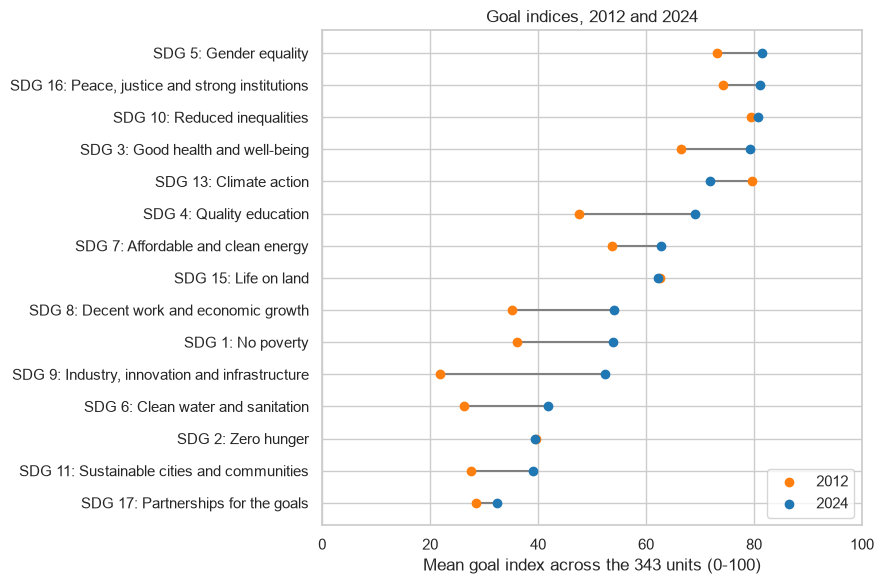

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
order = goals.sort_values("mean 2024").index
ylab = [f"{g}: {goals.loc[g, 'name']}" for g in order]
ax.hlines(ylab, goals.loc[order, "mean 2012"], goals.loc[order, "mean 2024"], color="grey", lw=1.5)
ax.scatter(goals.loc[order, "mean 2012"], ylab, color="tab:orange", label="2012", zorder=3)
ax.scatter(goals.loc[order, "mean 2024"], ylab, color="tab:blue", label="2024", zorder=3)
ax.set(xlabel="Mean goal index across the 343 units (0-100)", xlim=(0, 100),
       title="Goal indices, 2012 and 2024")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

What lies behind the three goals that did not advance? The mean of their indicators (in their original units) across the 343 units:

In [14]:
comp = []
for g in [13, 2, 15]:
    d = geo.dictionary(f"sdg{g:02d}")
    d = d[d["variable"].str.startswith(f"sdg{g}_")]
    vals = geo.load(f"sdg{g:02d}", variables=list(d["variable"])).groupby("year").mean(numeric_only=True)
    for v, lab in zip(d["variable"], d["label"]):
        comp.append({"goal": f"SDG {g}", "indicator": lab, "2012": vals.loc[2012, v], "2024": vals.loc[2024, v]})
pd.DataFrame(comp).set_index(["goal", "indicator"]).round(2)

2012   2024
goal   indicator                                                       
SDG 13 Families affected by extreme climate events (%)      9.44  40.04
       Climate-change vulnerability index (0-3)             1.53   1.45
       CO2 emissions from forest loss (t per person pe...  28.98  26.80
       CO2 emissions from transport (t per person per ...   0.17   0.69
       CO2 emissions from fires (t per person per year)    14.07  34.60
SDG 2  Obesity in women 15-49 (%)                          14.77  26.78
       Chronic malnutrition in children under 5 (%)        37.23  18.89
       Overweight in children under 5 (%)                   7.88   6.92
       Anaemia in women 15-49 (%)                          41.85  57.59
       Agricultural production (t per person per year)      2.27   3.87
       Agricultural yield (t per ha per year)               4.86   4.25
       Agricultural diversification index (0-1)             0.43   0.50
SDG 15 Area declared protected (%)                         12.08  17.45
       Forest loss rate (% per year)                        1.17   1.34
       Biodiversity loss from deforestation (index)         0.31   0.41
       Biodiversity loss from fires (index)                 0.78   2.36

- **Twelve of the 15 goals advanced** on average. The largest gains were in **SDG 9** (industry, innovation and infrastructure: 21.9 to 52.3, +30.4) and **SDG 4** (quality education, +21.5), both of which rose in every unit, followed by SDG 8 (decent work, +18.8), SDG 1 (no poverty, +17.8) and SDG 6 (clean water and sanitation, +15.5).
- **Three goals did not advance**: SDG 2 (zero hunger, −0.3) and SDG 15 (life on land, −0.3) were flat, and **SDG 13 (climate action) retreated** by 7.8 points, falling in 77.6% of the units.
  - In SDG 13 the average share of families affected by extreme climate events rose from 9.4% to 40.0% and CO₂ emissions from fires from 14.1 to 34.6 t per person per year.
  - In SDG 2, chronic malnutrition among children under 5 halved (37.2% to 18.9%), but obesity (14.8% to 26.8%) and anaemia (41.9% to 57.6%) among women of 15–49 rose. Weighted by population, SDG 2 fell by 6.2 points.
  - In SDG 15 more land was declared protected (12.1% to 17.5%), but the index of biodiversity loss from fires tripled (0.78 to 2.36).
- **Weighting by population** changes levels more than the direction of change. The cities score higher on most goals, but lower on SDG 16 (peace, justice and strong institutions: 56.6 weighted against 74.2 equal-weighted in 2012). The largest weighted gains are again SDG 9 (+25.5), SDG 8 (+24.5) and SDG 4 (+18.2).
- In 2024 the lowest goals are SDG 17 (partnerships, 32.3), SDG 11 (sustainable cities, 39.1), SDG 2 (39.4) and SDG 6 (41.8).

## 4. Convergence

Two questions, in the language of the growth literature:

- **β-convergence**: did municipalities that started lower improve faster, so that laggards catch up?
- **σ-convergence**: did the dispersion across municipalities narrow?

### β-convergence of the IDS

`geometrics` regresses each unit's annualised log growth of the IDS on its initial log level. With the periods stored as 2012 and 2024, the horizon is T = 12, so growth is per year and the half-life is in years. A negative slope β means convergence; it implies a speed λ = −ln(1 + βT)/T and a half-life ln 2/λ.

In [15]:
ggdf, gdf_long, gdict = geo.for_geometrics(geo.load("sdg", variables=["index_sdg"]))
gdf_long = gm.set_labels(gdf_long, gdict, set_panel=True)
w = gm.make_weights(ggdf, method="queen")          # Coipasa, an island, joins its nearest neighbour
print(w.geometrics_meta["spec"])

beta = gm.analyze_beta_convergence(gdf_long, "index_sdg", gdf=ggdf, w=w)
print(beta.interpret())
beta.fig

queen contiguity (1 island(s) attached to nearest neighbor), row-standardized, n=343


Across 343 units, the growth of **index_sdg** over a 12-period window is associated with its initial log level with a total slope of **-0.0287** (SE 0.00171), statistically significant at the 1% level.
The slope is negative — the β-convergence pattern: units that started lower tended to grow faster, narrowing initial gaps.
That slope implies a convergence speed of λ = 0.0351 per period and a half-life of about 19.7 periods — the time for half of an initial gap to close at this pace.

_These are associations, not causal effects. A causal reading needs a research design — see `explain('correlation_vs_causation')`._


The spatial error model accounts for spatially correlated shocks, which the Moran's I below shows are present:

In [16]:
beta_sem = gm.analyze_beta_convergence(gdf_long, "index_sdg", gdf=ggdf, w=w, model="sem")
print(beta_sem.interpret())

Across 343 units, the growth of **index_sdg** over a 12-period window is associated with its initial log level with a total slope of **-0.0321** (SE 0.00191), statistically significant at the 1% level.
The slope is negative — the β-convergence pattern: units that started lower tended to grow faster, narrowing initial gaps.
That slope implies a convergence speed of λ = 0.0405 per period and a half-life of about 17.1 periods — the time for half of an initial gap to close at this pace.
The SEM decomposition splits the total into a direct component of -0.0321 (own initial level) and no separate spillover component, under the weights: queen contiguity (1 island(s) attached to nearest neighbor), row-standardized, n=343.
The spatial-error parameter λ = 0.467 indicates spatially correlated unobservables: shocks to growth cluster geographically.

_These are associations, not causal effects. A causal reading needs a research design — see `explain('correlation_vs_causation')`._


The same question in points rather than logs: regress the change in the IDS on its 2012 level.

In [17]:
ols_ids = smf.ols("ids_change ~ index_sdg_2012", data=wide).fit(cov_type="HC1")
print(f"Change on initial level: slope {ols_ids.params['index_sdg_2012']:.3f} "
      f"(SE {ols_ids.bse['index_sdg_2012']:.3f}), R² {ols_ids.rsquared:.2f}")
print(f"Correlation of the 2012 IDS with its change: {wide['index_sdg_2012'].corr(wide['ids_change']):.2f}")
print(f"Correlation of the 2012 IDS with the 2024 IDS: {wide['index_sdg_2012'].corr(wide['index_sdg_2024']):.2f}")

Change on initial level: slope -0.216 (SE 0.024), R² 0.19
Correlation of the 2012 IDS with its change: -0.43
Correlation of the 2012 IDS with the 2024 IDS: 0.87


- **The IDS converged.** The slope of annual log growth on the initial log level is −0.0287 (SE 0.0017, R² 0.44): units that started lower grew faster. Because the periods are stored as years 2012 and 2024, `geometrics` uses a 12-year horizon, so its "periods" are years: the implied speed is 3.5% a year and the half-life about **19.7 years**, the time it would take to halve the initial gaps at this pace.
- The spatial error model gives a slightly faster convergence (−0.0321, half-life 17.1 years), with a strong spatial error parameter (λ = 0.467): shocks to growth are shared by neighbours.
- In points, each extra point of IDS in 2012 is associated with 0.22 fewer points of gain (SE 0.024, R² 0.19). The correlation of the 2012 IDS with its change is **−0.43**, while the ordering persists: the IDS of 2012 and 2024 correlate at **0.87**. Both match the Atlas.
- With two periods, part of a negative β can be regression to the mean (measurement noise in 2012 that does not repeat), so the speed is best read as an upper bound.

### β-convergence of multidimensional poverty

For poverty, a *bad*, convergence means that poverty fell more where it was higher. In levels, the change in the MPI is regressed on its 2012 level: a slope below zero means larger absolute reductions in poorer units, and a slope of −1 would mean poverty disappeared everywhere.

MPI change on MPI 2012: slope -0.641 (SE 0.016), R² 0.90
Units where the MPI fell: 343 of 343
MPI: mean 0.234 -> 0.063; population-weighted 0.133 -> 0.033
Log change on log MPI 2012: slope 0.242 (SE 0.037); MPI 2024 / MPI 2012: median 0.24


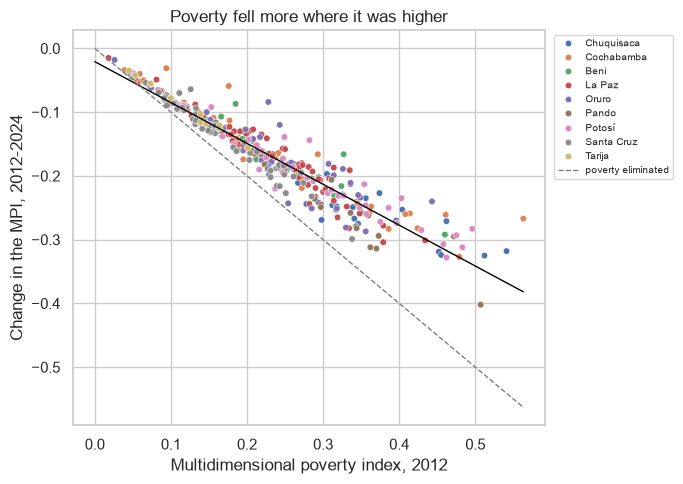

In [18]:
ols_mpi = smf.ols("mpi_change ~ sdg1_2_mpi_2012", data=wide).fit(cov_type="HC1")
print(f"MPI change on MPI 2012: slope {ols_mpi.params['sdg1_2_mpi_2012']:.3f} "
      f"(SE {ols_mpi.bse['sdg1_2_mpi_2012']:.3f}), R² {ols_mpi.rsquared:.2f}")
print(f"Units where the MPI fell: {(wide['mpi_change'] < 0).sum()} of {len(wide)}")
print(f"MPI: mean {wide['sdg1_2_mpi_2012'].mean():.3f} -> {wide['sdg1_2_mpi_2024'].mean():.3f}; "
      f"population-weighted {wmean(wide['sdg1_2_mpi_2012'], wide['population_2012']):.3f} -> "
      f"{wmean(wide['sdg1_2_mpi_2024'], wide['population_2024']):.3f}")

ratio = wide["sdg1_2_mpi_2024"] / wide["sdg1_2_mpi_2012"]
ols_rel = smf.ols("np.log(sdg1_2_mpi_2024 / sdg1_2_mpi_2012) ~ np.log(sdg1_2_mpi_2012)",
                  data=wide).fit(cov_type="HC1")
print(f"Log change on log MPI 2012: slope {ols_rel.params.iloc[1]:.3f} (SE {ols_rel.bse.iloc[1]:.3f}); "
      f"MPI 2024 / MPI 2012: median {ratio.median():.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=wide, x="sdg1_2_mpi_2012", y="mpi_change", hue="department", s=22, ax=ax)
xs = np.linspace(0, wide["sdg1_2_mpi_2012"].max(), 50)
ax.plot(xs, ols_mpi.params.iloc[0] + ols_mpi.params.iloc[1] * xs, color="black", lw=1)
ax.plot(xs, -xs, color="grey", ls="--", lw=1, label="poverty eliminated")
ax.set(xlabel="Multidimensional poverty index, 2012", ylabel="Change in the MPI, 2012-2024",
       title="Poverty fell more where it was higher")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

- **In absolute terms, poverty converged strongly.** The MPI fell in all 343 units, from a mean of 0.234 to 0.063 (population-weighted, 0.133 to 0.033). The slope of the change on the 2012 level is **−0.641** (SE 0.016, R² 0.90): every 0.1 of MPI in 2012 is associated with a reduction 0.064 larger. Poorer units cut poverty far more in points: about two thirds of any initial difference in poverty was closed.
- **In relative terms, it diverged.** The slope of the log change on the log 2012 level is **+0.242** (SE 0.037): proportional reductions were larger where poverty was already low. The median unit's MPI in 2024 is 24% of its 2012 value, but the poorest units kept a larger share of theirs. Absolute gaps narrowed while relative gaps widened, as the dispersion measures confirm.

### σ-convergence: dispersion in each period

`geometrics`' σ-convergence test needs at least three periods, so with two we compare the dispersion directly: the standard deviation (absolute gaps), and the coefficient of variation and the Gini coefficient (relative gaps).

In [19]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return float(2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n)

def dispersion(x):
    return {"sd": x.std(), "cv": x.std() / x.mean(), "gini": gini(x)}

sigma = pd.DataFrame({(var, y): dispersion(wide[f"{var}_{y}"])
                      for var in ["index_sdg", "sdg1_2_mpi"] for y in YEARS}).T
sigma.round(3)

sd     cv   gini
index_sdg  2012  5.819  0.116  0.065
           2024  5.264  0.088  0.049
sdg1_2_mpi 2012  0.106  0.450  0.254
           2024  0.044  0.696  0.367

In [20]:
goal_cv = pd.DataFrame({y: {f"SDG {g}": wide[f"index_sdg{g}_{y}"].std() / wide[f"index_sdg{g}_{y}"].mean()
                            for g in GOALS} for y in YEARS})
goal_cv["narrowed"] = goal_cv[2024] < goal_cv[2012]
print(f"Goals whose coefficient of variation fell: {goal_cv['narrowed'].sum()} of {len(GOALS)}")
goal_cv.round(3).T

Goals whose coefficient of variation fell: 11 of 15


,SDG 1,SDG 2,SDG 3,SDG 4,SDG 5,SDG 6,SDG 7,SDG 8,SDG 9,SDG 10,SDG 11,SDG 13,SDG 15,SDG 16,SDG 17
2012,0.493,0.19,0.162,0.222,0.062,0.478,0.322,0.255,0.496,0.096,0.387,0.156,0.266,0.146,0.573
2024,0.285,0.135,0.11,0.127,0.057,0.304,0.247,0.166,0.196,0.078,0.321,0.196,0.269,0.151,0.59
narrowed,True,True,True,True,True,True,True,True,True,True,True,False,False,False,False


- **The IDS shows σ-convergence** on every measure: the standard deviation fell from 5.82 to 5.26 points, the coefficient of variation from 0.116 to 0.088 and the Gini from 0.065 to 0.049.
- **Poverty narrowed in absolute terms but widened in relative terms**: the standard deviation of the MPI fell from 0.106 to 0.044, but its coefficient of variation rose from 0.450 to 0.696 and its Gini from 0.254 to 0.367. As poverty approaches zero in most units, what remains is increasingly concentrated in a few.
- **Eleven of the 15 goal indices became less dispersed** (relative to their means), most of all SDG 9 (0.496 to 0.196) and SDG 1 (0.493 to 0.285). Dispersion rose slightly in SDG 13, 15, 16 and 17.

## 5. Rank mobility

The Atlas ranks the 343 units by their IDS in each period (1 = best). How much did the ordering change?

In [21]:
from scipy.stats import spearmanr

wide["rank_change"] = wide["rank_sdg_2012"] - wide["rank_sdg_2024"]     # > 0: climbed
rho, p = spearmanr(wide["rank_sdg_2012"], wide["rank_sdg_2024"])
moves = wide["rank_change"].abs()
print(f"Spearman correlation of the ranks: {rho:.2f} (p = {p:.1g})")
print(f"Absolute rank change: mean {moves.mean():.0f}, median {moves.median():.0f}; "
      f"{(moves > 50).sum()} units moved more than 50 places, {(moves <= 10).sum()} at most 10")

cols = ["name", "department", "rank_sdg_2012", "rank_sdg_2024", "rank_change", "ids_change"]
print("\nLargest climbers:")
print(wide.nlargest(8, "rank_change")[cols].to_string(index=False))
print("\nLargest fallers:")
print(wide.nsmallest(8, "rank_change")[cols].to_string(index=False))

Spearman correlation of the ranks: 0.84 (p = 1e-93)
Absolute rank change: mean 40, median 29; 92 units moved more than 50 places, 80 at most 10

Largest climbers:
                      name department  rank_sdg_2012  rank_sdg_2024  rank_change  ids_change
      Cruz de Machacamarca      Oruro          317.0           90.0        227.0        20.5
                  Carangas      Oruro          306.0          103.0        203.0        19.4
                    Sicaya Cochabamba          318.0          154.0        164.0        17.6
              Todos Santos      Oruro          290.0          136.0        154.0        16.8
Villa Gualberto Villarroel Cochabamba          304.0          156.0        148.0        16.9
                  Bolpebra      Pando          250.0          125.0        125.0        15.5
                Santa Rosa      Pando          204.0           83.0        121.0        15.6
                    Escara      Oruro          293.0          179.0        114.0        15.1


A quintile transition matrix: rows are the IDS quintile in 2012 (Q1 = lowest), columns the quintile in 2024, and each cell the share of the row's units.

Units in the same quintile in both periods: 55%; staying rate by quintile: {'Q1': np.float64(0.67), 'Q2': np.float64(0.5), 'Q3': np.float64(0.38), 'Q4': np.float64(0.46), 'Q5': np.float64(0.77)}


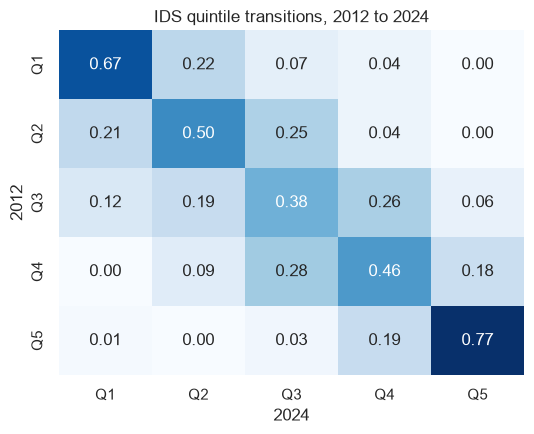

In [22]:
q = {y: pd.qcut(wide[f"index_sdg_{y}"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
     for y in YEARS}
trans = pd.crosstab(q[2012], q[2024], normalize="index").rename_axis(index="2012", columns="2024")
print(f"Units in the same quintile in both periods: {100 * (q[2012] == q[2024]).mean():.0f}%; "
      f"staying rate by quintile: {dict(zip(trans.index, np.diag(trans).round(2)))}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(trans, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("IDS quintile transitions, 2012 to 2024")
plt.tight_layout()
plt.show()

- **The ordering is persistent but far from fixed.** The Spearman correlation of the two rankings is 0.84. The median unit moved 29 places (mean 40); 92 units moved more than 50 places and 80 at most 10.
- **Climbers** are the large gainers of section 2, which started near the bottom: Cruz de Machacamarca rose from 317th to 90th (+227 places), Carangas from 306th to 103rd, Sicaya from 318th to 154th; four of the top eight are in Oruro and two in Pando.
- **Fallers** are mostly in Santa Cruz (five of the eight largest falls): San José de Chiquitos fell from 42nd to 283rd (−241), and Puerto Suárez and Roboré, both in the top 52 in 2012, fell more than 130 places. A small gain is a large fall in rank when nearly everyone else gained about ten points.
- **Quintiles.** 55% of the units are in the same IDS quintile in both periods. Persistence is highest at the extremes: 67% of the bottom quintile and 77% of the top quintile stay there, against 38–50% in the middle quintiles.

## 6. Spatial dynamics

### Global spatial autocorrelation

Moran's I with queen contiguity (the weights above) for the IDS in each period and for its change:

In [23]:
cs = wide[["ids_change"]].reset_index()
moran = {}
for y in YEARS:
    r = gm.explore_moran_plot(gdf_long, "index_sdg", gdf=ggdf, w=w, period=y, seed=SEED)
    moran[f"IDS {y}"] = (r.moran_i, r.p_sim)
r_change = gm.explore_moran_plot(cs, "ids_change", gdf=ggdf, w=w, entity="geo_id", seed=SEED,
                                 title="Moran scatterplot: change in the IDS, 2012-2024")
moran["Change 2012-2024"] = (r_change.moran_i, r_change.p_sim)
pd.DataFrame(moran, index=["Moran's I", "pseudo p"]).T.round(3)

,Moran's I,pseudo p
IDS 2012,0.432,0.001
IDS 2024,0.468,0.001
Change 2012-2024,0.223,0.001


In [24]:
r_change.fig

### Where progress clustered: LISA of the change

Local Moran statistics (999 permutations, 5% level) classify each unit: **High-High** units gained much and are surrounded by units that gained much; **Low-Low** units gained little among neighbours that gained little; High-Low and Low-High are outliers.

At the 0.05 significance level, 59 of 343 regions show significant local association: **18 High-High** hot spots (high values surrounded by high neighbors) and **26 Low-Low** cold spots (low surrounded by low) mark clustering, while **4 High-Low** and **11 Low-High** regions are spatial outliers that break with their surroundings. The remaining 284 regions are not significant — their local pattern is compatible with randomness.


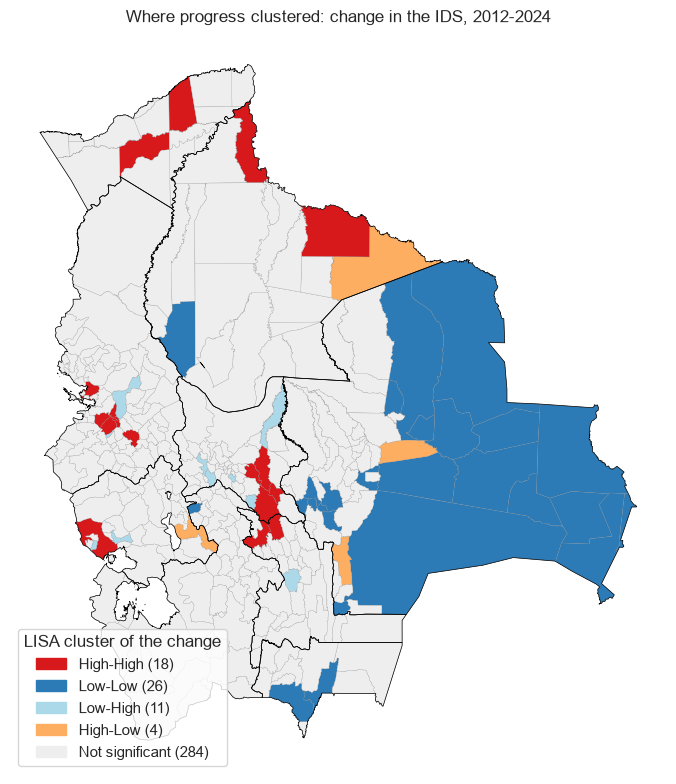

In [25]:
lisa = gm.explore_lisa_cluster_map(cs, "ids_change", gdf=ggdf, w=w, entity="geo_id",
                                   permutations=999, seed=SEED, tiles=None)
print(lisa.interpret().split("\n\n")[1])

LISA_COLORS = {"High-High": "#d7191c", "Low-Low": "#2c7bb6", "Low-High": "#abd9e9",
               "High-Low": "#fdae61", "Not significant": "#eeeeee"}
lmap = gdf.merge(lisa.df[["entity", "cluster"]], left_on="geo_id", right_on="entity")
fig, ax = plt.subplots(figsize=(8, 8))
for cl, color in LISA_COLORS.items():
    part = lmap[lmap["cluster"] == cl]
    if len(part):
        part.plot(ax=ax, color=color, edgecolor="grey", linewidth=0.15)
dep_lines.plot(ax=ax, color="black", linewidth=0.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LISA_COLORS.values()]
ax.legend(handles, [f"{c} ({(lmap['cluster'] == c).sum()})" for c in LISA_COLORS], loc="lower left",
          title="LISA cluster of the change")
ax.set_title("Where progress clustered: change in the IDS, 2012-2024")
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [26]:
summary_cl = (lmap[lmap["cluster"].isin(["High-High", "Low-Low"])]
              .groupby(["cluster", "department"])
              .agg(units=("geo_id", "size"), mean_change=("ids_change", "mean"),
                   mean_ids_2012=("index_sdg_2012", "mean"))
              .round(1))
summary_cl

units  mean_change  mean_ids_2012
cluster   department                                   
High-High Beni            2         10.8           50.5
          Chuquisaca      2         12.0           54.2
          Cochabamba      4         13.4           50.5
          La Paz          7         12.6           51.5
          Oruro           1         11.9           46.2
          Pando           2         10.2           47.7
Low-Low   Beni            1          6.2           47.1
          Potosí          1          8.9           55.2
          Santa Cruz     22          6.0           54.2
          Tarija          2          8.6           60.8

In [27]:
for cl in ["High-High", "Low-Low"]:
    part = lmap[lmap["cluster"] == cl].sort_values("ids_change", ascending=(cl == "Low-Low"))
    print(f"{cl}: mean IDS 2012 {part['index_sdg_2012'].mean():.1f}, mean change {part['ids_change'].mean():+.1f}")
    print(f"{cl}: " + ", ".join(f"{n} ({d}, {c:+.1f})" for n, d, c in
                                zip(part["name"], part["department"], part["ids_change"])), "\n")

High-High: mean IDS 2012 50.8, mean change +12.2
High-High: Totora (Cochabamba, +14.8), Laja (La Paz, +14.7), Aiquile (Cochabamba, +14.1), Viacha (La Paz, +13.9), Presto (Chuquisaca, +13.7), Achocalla (La Paz, +13.6), Omereque (Cochabamba, +13.2), El Alto (La Paz, +12.3), Sabaya (Oruro, +11.9), Huatajata (La Paz, +11.7), Sapahaqui (La Paz, +11.6), Pocona (Cochabamba, +11.5), Magdalena (Beni, +11.2), Achacachi (La Paz, +10.7), Puerto Rico (Pando, +10.3), Guayaramerín (Beni, +10.3), Sucre (Chuquisaca, +10.2), Ingavi (Pando, +10.1) 

Low-Low: mean IDS 2012 54.5, mean change +6.3
Low-Low: San José de Chiquitos (Santa Cruz, -2.7), Roboré (Santa Cruz, +1.2), Puerto Suárez (Santa Cruz, +2.3), Trigal (Santa Cruz, +3.8), Puerto Quijarro (Santa Cruz, +4.3), San Miguel de Velasco (Santa Cruz, +4.5), Postrervalle (Santa Cruz, +5.2), Pailón (Santa Cruz, +5.5), San Matías (Santa Cruz, +5.8), San Borja (Beni, +6.2), San Ignacio de Velasco (Santa Cruz, +6.4), Concepción (Santa Cruz, +6.5), Moromoro (S

- **Levels are clustered, and slightly more so in 2024**: Moran's I is 0.432 in 2012 and 0.468 in 2024 (both p = 0.001).
- **Progress itself is clustered** (I = 0.223, p = 0.001), though less than the levels: neighbours tended to advance at similar speeds.
- **Hot spots of progress** (18 High-High units) form a few groups: the La Paz altiplano around El Alto (El Alto, Viacha, Laja, Achocalla, Huatajata, Sapahaqui, Achacachi), the valleys of Cochabamba and Chuquisaca (Totora, Aiquile, Omereque, Pocona, Presto, Sucre), the far north (Puerto Rico and Ingavi in Pando; Guayaramerín and Magdalena in Beni) and Sabaya on the Oruro altiplano. They gained 10.1 to 14.8 points.
- **Cold spots** (26 Low-Low units) are almost all in **Santa Cruz** (22): the Chiquitania and the border with Brazil (San José de Chiquitos, Roboré, Puerto Suárez, Puerto Quijarro, San Matías, San Ignacio de Velasco, Concepción), the city of Santa Cruz de la Sierra and the Santa Cruz valleys (Samaipata, Pampagrande, Quirusillas, Trigal, Postrervalle), and Charagua and Cuevo in the Chaco. Two are in Tarija, one in Potosí (Llallagua) and one in Beni (San Borja).
- The cold spots started *above* the hot spots (mean IDS in 2012: 54.5 against 50.8) and gained about half as much (6.3 against 12.2 points): the spatial pattern of progress is, in large part, convergence seen on the map.

## 7. Takeaways

- **Broad progress.** Between about 2012 and 2024 the Sustainable Development Index rose in 342 of Bolivia's 343 municipalities and indigenous autonomies, by 10.0 points on average (population-weighted, 57.9 to 66.8). Only San José de Chiquitos fell.
- **Driven by infrastructure, education, work and poverty.** SDG 9 (+30.4), SDG 4 (+21.5), SDG 8 (+18.8) and SDG 1 (+17.8) advanced most. Climate action retreated (−7.8), with more families affected by extreme events and more emissions from fires, and zero hunger and life on land stood still.
- **Convergence.** Units that started lower gained more (correlation of the initial IDS with its change −0.43; β = −0.029, half-life about 20 years), and the dispersion of the IDS narrowed (Gini 0.065 to 0.049). Multidimensional poverty fell everywhere and fell most, in points, where it was highest, but relative gaps in poverty widened (Gini 0.254 to 0.367).
- **Persistent ordering, with mobility.** Ranks correlate at 0.84 and 55% of the units stay in their quintile; the Oruro altiplano climbed most and the Chiquitania of Santa Cruz fell most.
- **Geography of progress.** Levels and changes are spatially clustered (Moran's I 0.47 for the 2024 IDS, 0.22 for the change). Progress concentrated around El Alto, in the Cochabamba–Chuquisaca valleys and in the north, and lagged in eastern Santa Cruz.
- **Caveats.** Two nominal periods, each mixing indicators of different reference years; indices rescaled between fixed bounds, so a goal's change depends on those bounds; associations, not causal effects.

Related notebooks: [`eda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/eda.ipynb) (multidimensional poverty in both censuses), [`esda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb) (spatial clustering) and [`embeddings_mpi_ml`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/embeddings_mpi_ml.ipynb) (predicting poverty from satellite embeddings).